# Feature-Matching

The previous experiment (`010_feature_matching.ipynb`) had a problem: Feature-Points were matched very good between reference-image and current-image. But the Reference-Points were not around the region of interrest, but in another plane (Screws, black ring around the meter).

This experiment uses as reference.image ohly the meter dial (German: Ziffernblatt) of the water-meter. 


In [1]:
from collections.abc import Sequence

import cv2
import matplotlib.pyplot as plt
import numpy as np

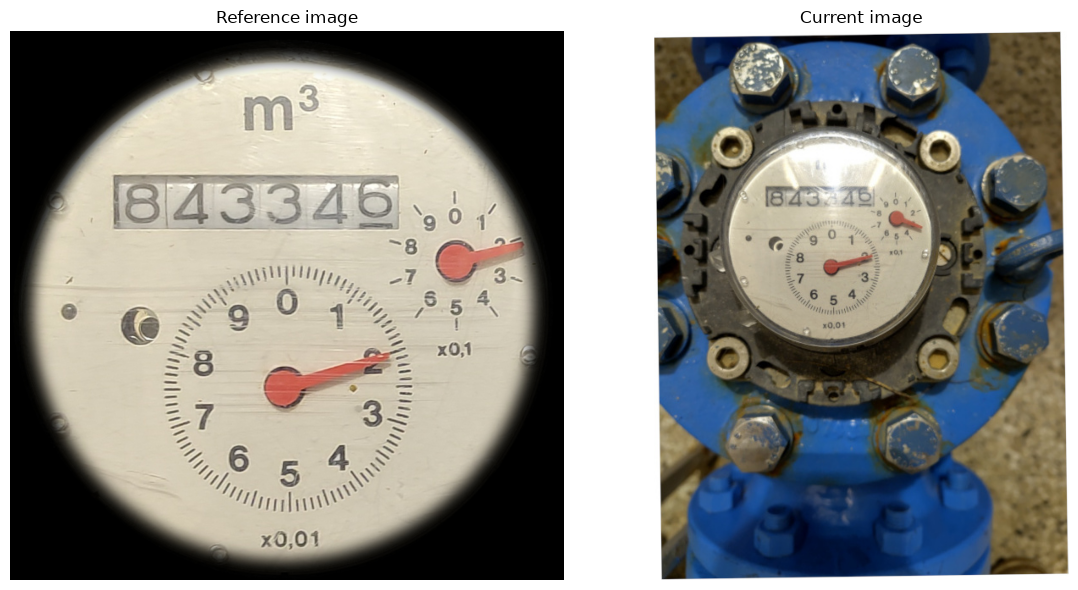

In [2]:
reference_image : np.ndarray
current_image : np.ndarray

REFERENCE_IMAGE_PATH = "data/2026-10-32_Fotos_water-meter/2026-11-08_water-meter-dial_reference-image_v2.jpg"
CURRENT_IMAGE_PATH = "data/2026-10-32_Fotos_water-meter/IMG_20261029_121646.jpg"

rv = cv2.imread(REFERENCE_IMAGE_PATH, cv2.IMREAD_COLOR)
assert isinstance(rv, np.ndarray), "Reference image not found."
reference_image = rv

rv = cv2.imread(CURRENT_IMAGE_PATH, cv2.IMREAD_COLOR)
assert isinstance(rv, np.ndarray), "Current image not found."
current_image = rv

# AI-Generated: Show both images side by side using matplotlib
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(reference_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Reference image")
axes[1].imshow(cv2.cvtColor(current_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Current image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## ROI in Reference Image

Select the ROI in the reference image using `cv2.selectROI()`:

```python
roi_in_reference = cv2.selectROI("Select ROI in Reference Image", reference_image)
```

To avoid the need to select the ROI every time, the position and size of the ROIth was measuered with GIMP:

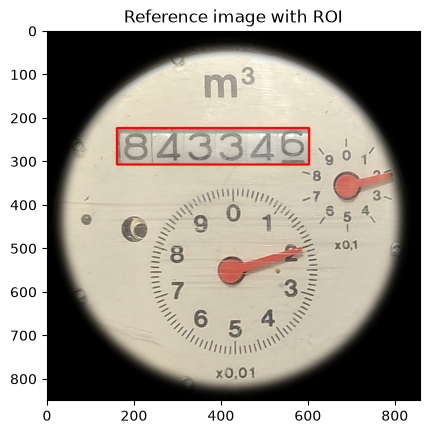

In [3]:
roi_in_reference : tuple[int,int,int,int]= (161, 223, 442, 84)  # (x, y, width, height) of the ROI in the reference image

ref_copy = reference_image.copy()
# Draw a rectangle around the ROI in the reference image
x1, y1 = roi_in_reference[0], roi_in_reference[1]
x2, y2 = x1 + roi_in_reference[2], y1 + roi_in_reference[3]
cv2.rectangle(ref_copy, (x1, y1), (x2, y2), (0, 0, 255), 3)
plt.imshow(cv2.cvtColor(ref_copy, cv2.COLOR_BGR2RGB))
plt.title("Reference image with ROI")
plt.show()

## Feature Matching

### Features in Reference-Image

In [4]:
reference_image_gray = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)

keypoints_reference: Sequence[cv2.KeyPoint]
descriptors_reference: np.ndarray

sift = cv2.SIFT.create()
keypoints_reference, descriptors_reference = sift.detectAndCompute(reference_image, None)

In [5]:
print(f"Number of detected Keypoints: {len(keypoints_reference)}")
print("First Keypoint:")
print(f"Location x,y {keypoints_reference[0].pt}")
print(f"Size (sigma): {keypoints_reference[0].size}")
print(f"Angle: {keypoints_reference[0].angle}")
print(f"Response: {keypoints_reference[0].response}")
print(f"Octave: {keypoints_reference[0].octave}")

Number of detected Keypoints: 1806
First Keypoint:
Location x,y (68.43612670898438, 273.82958984375)
Size (sigma): 1.9852418899536133
Angle: 52.0875358581543
Response: 0.015159069560468197
Octave: 7275007


Locations: Maimum x,y coordinates of features lie slightly outside the image.

In [6]:
max( kp.pt[0] for kp in keypoints_reference), max( kp.pt[1] for kp in keypoints_reference)

(802.448486328125, 806.5985717773438)

Each keypoint has a "Descriptor" which is a vector of 128 values that describes the local image patch around the keypoint. The descriptor is used to match keypoints between images.

In [7]:
print( descriptors_reference.shape )
print( descriptors_reference.dtype )

(1806, 128)
float32


## Features in Current-Image

In [8]:
keypoints_current: Sequence[cv2.KeyPoint]
descriptors_current: np.ndarray

current_image_gray = cv2.cvtColor(current_image, cv2.COLOR_BGR2GRAY)
keypoints_current, descriptors_current = sift.detectAndCompute(current_image, None)

In [9]:
print(f"Number of detected Keypoints: {len(keypoints_current)}")
print("First Keypoint:")
print(f"Location x,y {keypoints_current[0].pt}")
print(f"Size (sigma): {keypoints_current[0].size}")
print(f"Angle: {keypoints_current[0].angle}")
print(f"Response: {keypoints_current[0].response}")
print(f"Octave: {keypoints_current[0].octave}")

Number of detected Keypoints: 1479
First Keypoint:
Location x,y (3.775491952896118, 148.2262725830078)
Size (sigma): 2.41056752204895
Angle: 183.3555450439453
Response: 0.04889306426048279
Octave: 4588287


In [10]:
assert descriptors_current.shape == ( len(descriptors_current), 128 )

## Matching Features

A Brute-Force Matcher finds descriptors in the reference image, that are similar to the descriptors in the current image.

For SIFT the `cv2.NORM_L2` norm has to be used. If ORB was used instead of SIFT, the `cv2.NORM_HAMMING` norm would have to be used.

The `knnMatch() with `k=2` returns for each descritpr in the reference image two descriptors in the current image that have the smallest distance to the descriptor in the reference image.


In [11]:
brute_force_mathcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
raw : Sequence[Sequence[cv2.DMatch]] = brute_force_mathcher.knnMatch(
            queryDescriptors=descriptors_reference, 
            trainDescriptors=descriptors_current, 
            k=2
            )

In [12]:
print(f"Number of matches: {len(raw)}")
print(f"Each mach contains two matches, the closest and the second closest match: {all(len(m)==2 for m in raw)}")
print("First match - closest match:")
print(f"Indices : queryIdx: {raw[0][0].queryIdx}, imgIdx={raw[0][0].imgIdx}, trainIdx={raw[0][0].trainIdx}")
print(f"Distance: {raw[0][0].distance}")
print("First match - second closest match:")
print(f"Indices : queryIdx: {raw[0][1].queryIdx}, imgIdx={raw[0][1].imgIdx}, trainIdx={raw[0][1].trainIdx}")
print(f"Distance: {raw[0][1].distance}")

Number of matches: 1806
Each mach contains two matches, the closest and the second closest match: True
First match - closest match:
Indices : queryIdx: 0, imgIdx=0, trainIdx=444
Distance: 362.32305908203125
First match - second closest match:
Indices : queryIdx: 0, imgIdx=0, trainIdx=178
Distance: 372.2042541503906


## Leave only "good" matches with the Lowe's ratio test:

The distance of the second closest match must be at least 0.75 times the distance of the closest match. This is called Lowe's ratio test.

The remaining good_matches are sorted by their distance.

In [13]:
MIN_MATCH_COUNT = 15
MATCH_RATIO = 0.75
good_matches: list[cv2.DMatch]
good_matches = [m for m, n in raw if m.distance < MATCH_RATIO * n.distance]
good_matches.sort(key=lambda match: match.distance)

if len(good_matches) < MIN_MATCH_COUNT:
    print(f"!!!WARNING!!!: Not enough good matches found. Found {len(good_matches)}, but need at least {MIN_MATCH_COUNT}.") 

print(f"Number of good matches: {len(good_matches)}")
for i, match in enumerate(good_matches[:10]):
    print(f"Good match {i}: queryIdx: {match.queryIdx}, imgIdx: {match.imgIdx}, trainIdx: {match.trainIdx}, distance: {match.distance}")

Number of good matches: 115
Good match 0: queryIdx: 1111, imgIdx: 0, trainIdx: 790, distance: 43.11612319946289
Good match 1: queryIdx: 1110, imgIdx: 0, trainIdx: 789, distance: 46.475799560546875
Good match 2: queryIdx: 1091, imgIdx: 0, trainIdx: 786, distance: 50.59644317626953
Good match 3: queryIdx: 395, imgIdx: 0, trainIdx: 635, distance: 56.99122619628906
Good match 4: queryIdx: 471, imgIdx: 0, trainIdx: 653, distance: 85.24083709716797
Good match 5: queryIdx: 1390, imgIdx: 0, trainIdx: 856, distance: 93.94147491455078
Good match 6: queryIdx: 507, imgIdx: 0, trainIdx: 456, distance: 95.5039291381836
Good match 7: queryIdx: 472, imgIdx: 0, trainIdx: 654, distance: 96.91748809814453
Good match 8: queryIdx: 578, imgIdx: 0, trainIdx: 456, distance: 105.66929626464844
Good match 9: queryIdx: 748, imgIdx: 0, trainIdx: 713, distance: 110.44908142089844


The `good_matches` now contain the indices of the keypoints in the reference image (`queryIdx`) and the indices of the related keypoints in the current image (`trainIdx`) that are considered to be same points (good matches).

In [14]:
def draw_matches(reference_image: np.ndarray, 
                 current_image: np.ndarray, 
                 keypoints_reference: Sequence[cv2.KeyPoint], 
                 keypoints_current: Sequence[cv2.KeyPoint], 
                 good_matches: list, 
                 num_matches: int | None = None) -> None:
    if num_matches is None:
        num_matches = len(good_matches)
    line_width: int = 3 if num_matches <= 15 else 2

    SPACE = 20
    height = max(reference_image.shape[0], current_image.shape[0])
    width = reference_image.shape[1] + SPACE + current_image.shape[1]
    canvas = np.full((height, width, 3), 255, dtype=np.uint8)
    canvas[:reference_image.shape[0], :reference_image.shape[1]] = reference_image
    x_offset = reference_image.shape[1] + SPACE
    canvas[:current_image.shape[0], x_offset:] = current_image

    rng = np.random.default_rng()
    for m in good_matches[:num_matches]:
        color = tuple(int(c) for c in rng.integers(0, 256, size=3))

        x1, y1 = keypoints_reference[m.queryIdx].pt
        pt_ref = (round(x1), round(y1))

        x2, y2 = keypoints_current[m.trainIdx].pt
        pt_cur = (round(x2) + x_offset, round(y2))
        cv2.line(canvas, pt_ref, pt_cur, color, line_width)
        cv2.circle(canvas, pt_ref, 10, color, line_width)
        cv2.circle(canvas, pt_cur, 10, color, line_width)

    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

The first 10 good-matches:

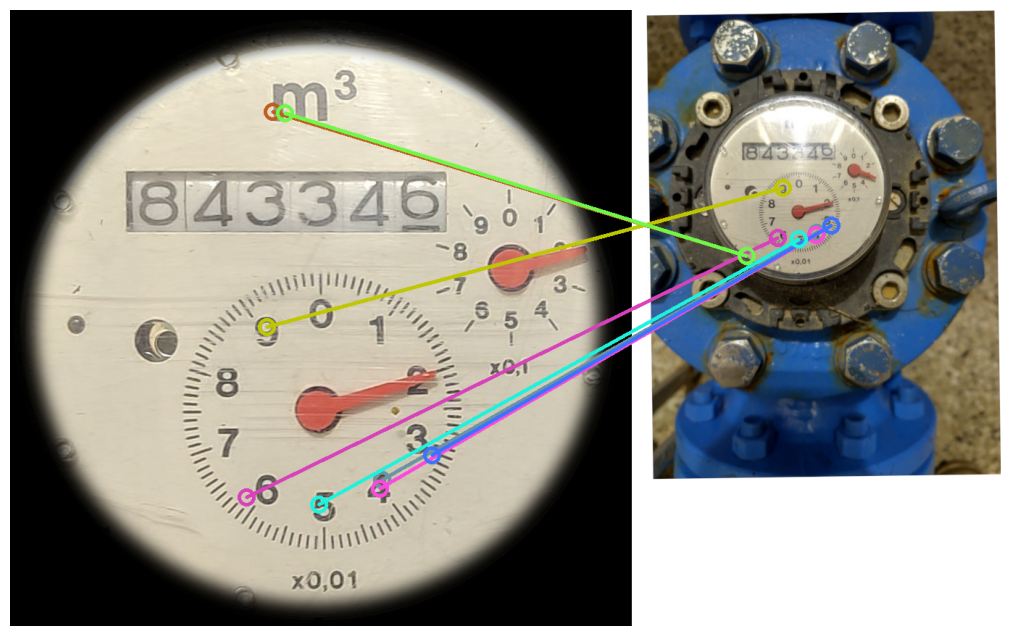

In [15]:
assert reference_image is not None, "Reference image not found."
assert current_image is not None, "Current image not found."

draw_matches(reference_image, 
             current_image, 
             keypoints_reference, 
             keypoints_current, 
             good_matches,
             num_matches=10)

All good-matches:

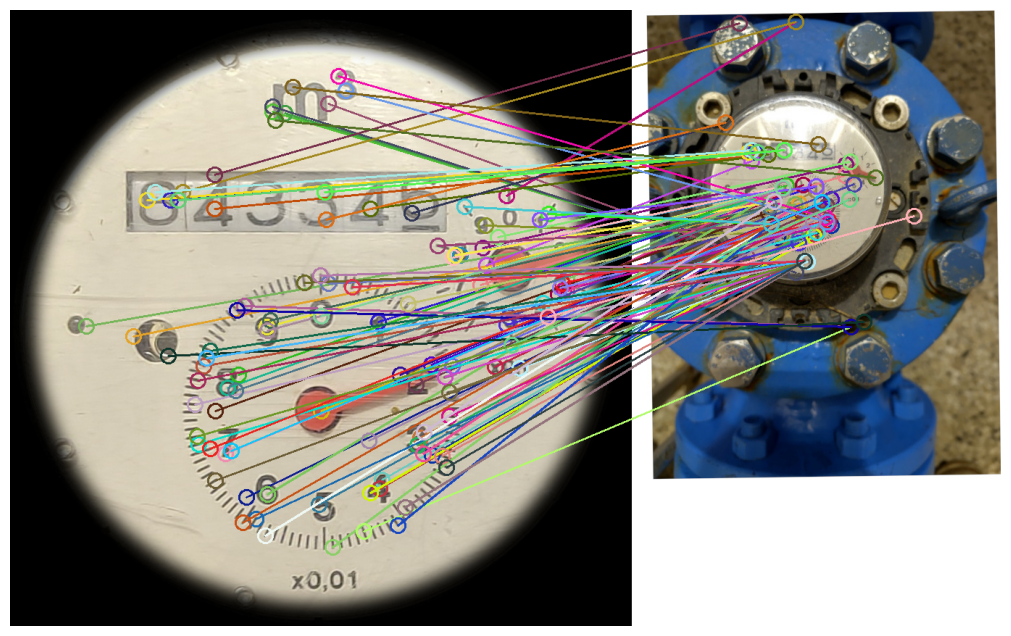

In [16]:
draw_matches(reference_image, 
             current_image, 
             keypoints_reference, 
             keypoints_current, 
             good_matches)

The last 10 good-matches: They should be the worst matches, because their distance is the largest: But it seems that the distance is not a good measure for the quality of the match. Most of the last 10 best-matches are actually very good matches.

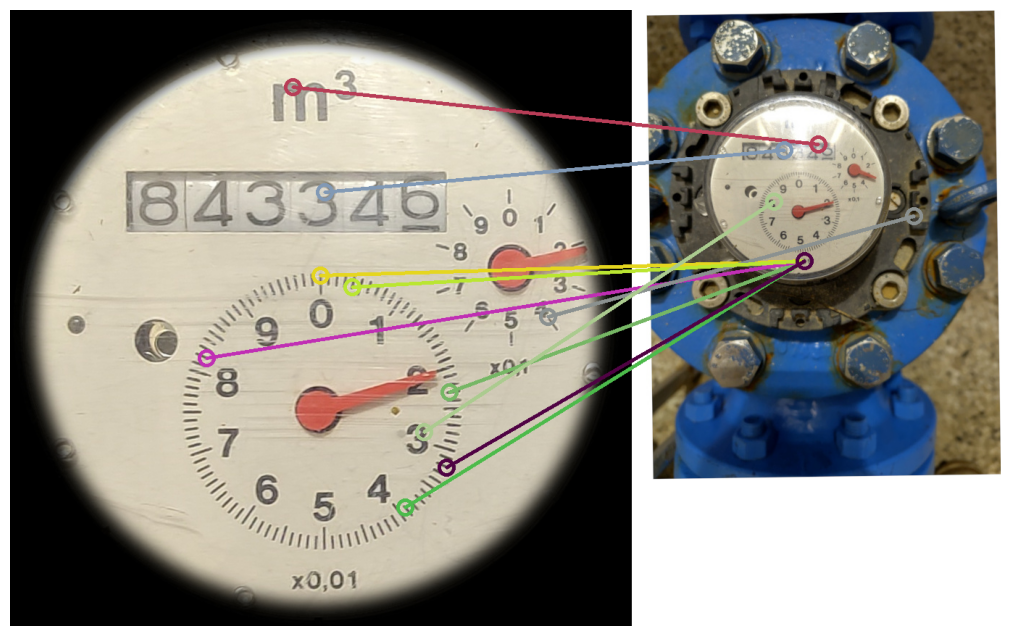

In [17]:
draw_matches(reference_image, 
             current_image, 
             keypoints_reference, 
             keypoints_current, 
             good_matches[-10:])

## Homography Matrix

First create "lists" with (feature-)Point-Coordinate in the Reference-Image and in the current image.

In [18]:
# Minimum Number of good-mathches
RANSAC_THRESH = 5.0     # px. Tolance for homography estimation


points_reference = np.zeros( (len(good_matches), 1, 2), dtype=np.float32)
points_current = np.zeros( (len(good_matches), 1, 2), dtype=np.float32)

for i, match in enumerate(good_matches):
    points_reference[i, 0] = np.array(keypoints_reference[match.queryIdx].pt)
    points_current[i, 0] = np.array(keypoints_current[match.trainIdx].pt)

print(points_reference[:5])
print()
print(points_current[:5])


[[[512.61426 648.1345 ]]

 [[512.61426 648.1345 ]]

 [[509.9154  659.89374]]

 [[326.46603 671.54456]]

 [[353.51874 437.37567]]]

[[[235.09515 306.73328]]

 [[235.09515 306.73328]]

 [[234.45459 310.2821 ]]

 [[180.77962 313.50134]]

 [[188.41255 245.01872]]]


Now create the Homography

In [19]:

# Homography RANSAC tolerates outliers (reflections, dirt)

homography_matrix, mask = cv2.findHomography(points_reference, 
                             points_current, 
                             cv2.RANSAC, 
                             RANSAC_THRESH)

assert homography_matrix is not None, "Homography estimation failed."

homography_matrix

array([[ 2.69855619e-01,  1.00747718e-02,  8.70015445e+01],
       [-1.77375781e-02,  2.92999929e-01,  1.21485140e+02],
       [-6.31677219e-05,  2.78468563e-05,  1.00000000e+00]])

In [20]:
homography_inverse = np.linalg.inv(homography_matrix)
homography_inverse

array([[ 3.62822055e+00, -9.58622538e-02, -3.04014953e+02],
       [ 1.26073768e-01,  3.44950556e+00, -4.30032280e+02],
       [ 2.25675669e-04, -1.02113286e-04,  9.92771115e-01]])

Now compute the supposed ROI-Region in the current-Image:

In [21]:
x, y, w, h = roi_in_reference
roi_corners_reference = np.array(
                   [[x, y], [x + w, y],
                    [x + w, y + h], [x, y + h]], dtype=np.int32).reshape(-1, 1, 2)
roi_corners_current = cv2.perspectiveTransform(roi_corners_reference.astype(np.float32), homography_matrix)

roi_corners_current = roi_corners_current.reshape(-1, 2).round().astype(int)
roi_corners_current

array([[133, 185],
       [260, 182],
       [261, 207],
       [134, 209]])

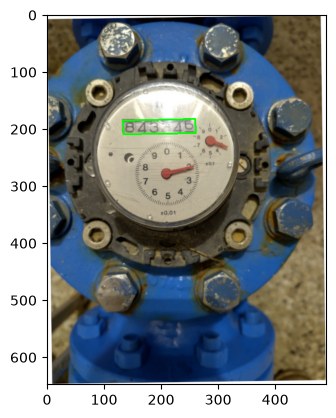

In [22]:
current_image_copy = current_image.copy()
cv2.polylines(current_image_copy, [roi_corners_current], isClosed=True, color=(0, 255, 0), thickness=2)
plt.imshow(cv2.cvtColor(current_image_copy, cv2.COLOR_BGR2RGB))

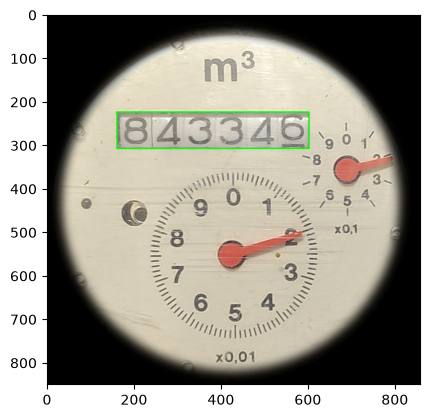

In [23]:
reference_image_copy = reference_image.copy()
cv2.polylines(reference_image_copy, [roi_corners_reference], isClosed=True, color=(0, 255, 0), thickness=2)
plt.imshow(cv2.cvtColor(reference_image_copy, cv2.COLOR_BGR2RGB))

Transformed original-Image with marked estimated ROI:

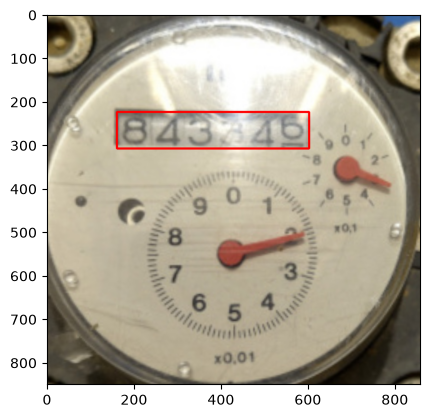

In [24]:
# Warp the current image into the reference image's coordinate frame
h_ref, w_ref = reference_image.shape[:2]
current_warped = cv2.warpPerspective(current_image, homography_inverse, (w_ref, h_ref))

current_warped_copy = current_warped.copy()
x1, y1 = roi_in_reference[0], roi_in_reference[1]
x2, y2 = x1 + roi_in_reference[2], y1 + roi_in_reference[3]
cv2.rectangle(current_warped_copy, (x1, y1), (x2, y2), (0, 0, 255), 3)
plt.imshow(cv2.cvtColor(current_warped_copy, cv2.COLOR_BGR2RGB))    

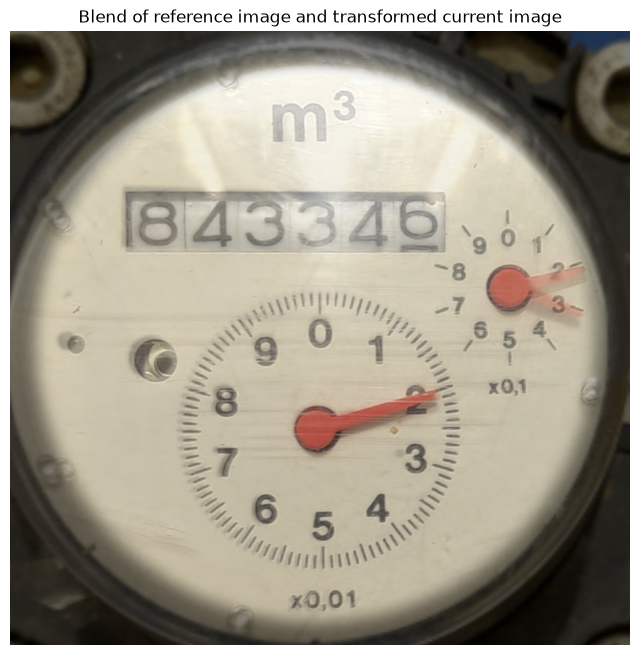

In [25]:
# Blend reference and warped current image
blended = cv2.addWeighted(reference_image, 0.5, current_warped, 0.5, 0)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
plt.title("Blend of reference image and transformed current image")
plt.axis("off")
plt.show()

Conclusion: With the better reference-image, the ROI is found very well. Yet, there are still features that are matched badly to the outside of the meter-dial.